In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn

print("P05 environment ready!")

P05 environment ready!


In [2]:
from pathlib import Path
import pandas as pd

# Dataset location
DATA_PATH = Path(r"D:\archive (1)\IMDB Dataset.csv")

# Load dataset
df = pd.read_csv(DATA_PATH)

# Display basic information
print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)
print("Columns:", df.columns.tolist())

df.head()

Dataset loaded successfully!
Dataset shape: (50000, 2)
Columns: ['review', 'sentiment']


,review,sentiment
0,One of the other reviewers has mentioned that ...,positive
1,A wonderful little production. <br /><br />The...,positive
2,I thought this was a wonderful way to spend ti...,positive
3,Basically there's a family where a little boy ...,negative
4,"Petter Mattei's ""Love in the Time of Money"" is...",positive


In [3]:
# Check missing values
print("Missing values:")
print(df.isnull().sum())

# Check sentiment distribution
print("\nSentiment distribution:")
print(df["sentiment"].value_counts())

# Check sentiment percentages
print("\nSentiment percentages:")
print((df["sentiment"].value_counts(normalize=True) * 100).round(2))

# Check duplicate reviews
print("\nExact duplicate reviews:", df.duplicated(subset=["review"]).sum())

Missing values:
review       0
sentiment    0
dtype: int64

Sentiment distribution:
sentiment
positive    25000
negative    25000
Name: count, dtype: int64

Sentiment percentages:
sentiment
positive    50.0
negative    50.0
Name: proportion, dtype: float64

Exact duplicate reviews: 418


In [4]:
# Calculate review length in words
df["review_length"] = df["review"].str.split().str.len()

# Summary statistics by sentiment
print(df.groupby("sentiment")["review_length"].describe().round(2))

             count    mean     std   min    25%    50%    75%     max
sentiment                                                            
negative   25000.0  229.46  164.95   4.0  128.0  174.0  278.0  1522.0
positive   25000.0  232.85  177.50  10.0  125.0  172.0  284.0  2470.0


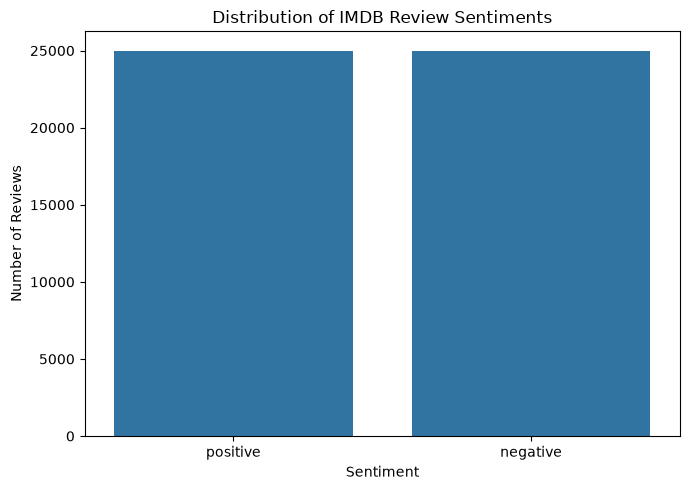

In [5]:
plt.figure(figsize=(7, 5))

sns.countplot(data=df, x="sentiment")

plt.title("Distribution of IMDB Review Sentiments")
plt.xlabel("Sentiment")
plt.ylabel("Number of Reviews")

plt.tight_layout()
plt.show()

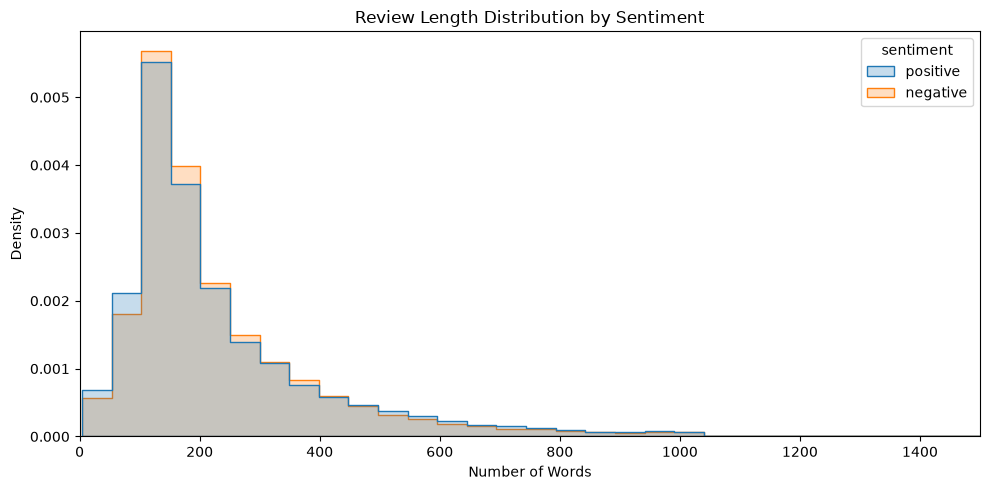

In [6]:
plt.figure(figsize=(10, 5))

sns.histplot(
    data=df,
    x="review_length",
    hue="sentiment",
    bins=50,
    element="step",
    stat="density",
    common_norm=False
)

plt.xlim(0, 1500)
plt.title("Review Length Distribution by Sentiment")
plt.xlabel("Number of Words")
plt.ylabel("Density")

plt.tight_layout()
plt.show()

In [7]:
for i, row in df.head(5).iterrows():
    print(f"\nReview {i + 1}")
    print("Sentiment:", row["sentiment"])
    print("Text:", row["review"][:1000])
    print("-" * 80)


Review 1
Sentiment: positive
Text: One of the other reviewers has mentioned that after watching just 1 Oz episode you'll be hooked. They are right, as this is exactly what happened with me.<br /><br />The first thing that struck me about Oz was its brutality and unflinching scenes of violence, which set in right from the word GO. Trust me, this is not a show for the faint hearted or timid. This show pulls no punches with regards to drugs, sex or violence. Its is hardcore, in the classic use of the word.<br /><br />It is called OZ as that is the nickname given to the Oswald Maximum Security State Penitentary. It focuses mainly on Emerald City, an experimental section of the prison where all the cells have glass fronts and face inwards, so privacy is not high on the agenda. Em City is home to many..Aryans, Muslims, gangstas, Latinos, Christians, Italians, Irish and more....so scuffles, death stares, dodgy dealings and shady agreements are never far away.<br /><br />I would say the main 

In [8]:
# Count exact duplicate reviews
duplicate_count = df.duplicated(subset=["review"]).sum()

# Count unique reviews
unique_count = df["review"].nunique()

# Check reviews that have conflicting sentiment labels
label_counts = df.groupby("review")["sentiment"].nunique()
conflicting_count = (label_counts > 1).sum()

print("Total reviews:", len(df))
print("Exact duplicate rows:", duplicate_count)
print("Unique review texts:", unique_count)
print("Unique reviews with conflicting labels:", conflicting_count)

Total reviews: 50000
Exact duplicate rows: 418
Unique review texts: 49582
Unique reviews with conflicting labels: 0


In [9]:
# Check whether exact duplicate texts have consistent labels
label_counts = df.groupby("review")["sentiment"].nunique()
conflicting_reviews = label_counts[label_counts > 1].index

print("Rows before duplicate handling:", len(df))
print("Rows with conflicting review labels:",
      df["review"].isin(conflicting_reviews).sum())

print("Rows after removing exact duplicate texts:",
      len(df.drop_duplicates(subset=["review"])))

Rows before duplicate handling: 50000
Rows with conflicting review labels: 0
Rows after removing exact duplicate texts: 49582


In [10]:
# Remove exact duplicate review texts
df_unique = df.drop_duplicates(subset=["review"]).copy()

print("Unique dataset shape:", df_unique.shape)
print("\nSentiment distribution after deduplication:")
print(df_unique["sentiment"].value_counts())

Unique dataset shape: (49582, 3)

Sentiment distribution after deduplication:
sentiment
positive    24884
negative    24698
Name: count, dtype: int64


In [11]:
from sklearn.model_selection import GroupShuffleSplit

# Use the original 50,000 rows
X = df["review"]
y = df["sentiment"]

# Assign identical review texts to the same group
groups = df["review"].factorize()[0]

# Split so identical reviews cannot cross train/test
splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=42
)

train_idx, test_idx = next(
    splitter.split(X, y, groups=groups)
)

X_train = X.iloc[train_idx]
X_test = X.iloc[test_idx]
y_train = y.iloc[train_idx]
y_test = y.iloc[test_idx]

print("Training reviews:", len(X_train))
print("Test reviews:", len(X_test))

print("\nTraining sentiment distribution:")
print(y_train.value_counts())

print("\nTest sentiment distribution:")
print(y_test.value_counts())

print(
    "\nOverlapping review texts:",
    len(set(X_train) & set(X_test))
)

Training reviews: 40006
Test reviews: 9994

Training sentiment distribution:
sentiment
positive    20004
negative    20002
Name: count, dtype: int64

Test sentiment distribution:
sentiment
negative    4998
positive    4996
Name: count, dtype: int64

Overlapping review texts: 0


In [12]:
# Verify split sizes
print("Training samples:", len(X_train))
print("Test samples:", len(X_test))

# Check for duplicate leakage
overlap = set(X_train) & set(X_test)
print("Overlapping review texts:", len(overlap))

# Check class distribution
print("\nTraining distribution:")
print(y_train.value_counts())

print("\nTest distribution:")
print(y_test.value_counts())

Training samples: 40006
Test samples: 9994
Overlapping review texts: 0

Training distribution:
sentiment
positive    20004
negative    20002
Name: count, dtype: int64

Test distribution:
sentiment
negative    4998
positive    4996
Name: count, dtype: int64


In [13]:
import numpy as np
import pandas as pd
from sklearn.model_selection import StratifiedGroupKFold

X = df["review"]
y = df["sentiment"]
groups = df["review"].factorize()[0]

# Search for a 5-fold stratified, group-aware split.
# One fold becomes the 10,000-review test set.
cv = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

best_split = None
best_score = float("inf")

for train_idx, test_idx in cv.split(X, y, groups):
    # Prefer exactly 10,000 test rows and balanced class proportions.
    size_error = abs(len(test_idx) - 10000)

    train_positive = (y.iloc[train_idx] == "positive").mean()
    test_positive = (y.iloc[test_idx] == "positive").mean()

    balance_error = (
        abs(train_positive - 0.5)
        + abs(test_positive - 0.5)
    )

    score = size_error + 10000 * balance_error

    if score < best_score:
        best_score = score
        best_split = (train_idx, test_idx)

train_idx, test_idx = best_split

X_train = X.iloc[train_idx]
X_test = X.iloc[test_idx]
y_train = y.iloc[train_idx]
y_test = y.iloc[test_idx]

print("Training samples:", len(X_train))
print("Test samples:", len(X_test))

print("\nTraining labels:")
print(y_train.value_counts())

print("\nTest labels:")
print(y_test.value_counts())

print(
    "\nOverlapping review texts:",
    len(set(X_train).intersection(set(X_test)))
)

Training samples: 40000
Test samples: 10000

Training labels:
sentiment
positive    20000
negative    20000
Name: count, dtype: int64

Test labels:
sentiment
negative    5000
positive    5000
Name: count, dtype: int64

Overlapping review texts: 0


In [14]:
from pathlib import Path
import pandas as pd

processed_dir = Path("../data/processed")
processed_dir.mkdir(parents=True, exist_ok=True)

train_df = pd.DataFrame({
    "review": X_train,
    "sentiment": y_train
})

test_df = pd.DataFrame({
    "review": X_test,
    "sentiment": y_test
})

train_df.to_csv(processed_dir / "train.csv", index=False)
test_df.to_csv(processed_dir / "test.csv", index=False)

print("Saved train.csv:", train_df.shape)
print("Saved test.csv:", test_df.shape)

Saved train.csv: (40000, 2)
Saved test.csv: (10000, 2)


In [15]:
from pathlib import Path
import pandas as pd

# Create directory for processed data
SPLIT_DIR = Path("../data/processed")
SPLIT_DIR.mkdir(parents=True, exist_ok=True)

# Save training data
train_df = pd.DataFrame({
    "review": X_train,
    "sentiment": y_train
})

train_df.to_csv(SPLIT_DIR / "train.csv", index=False)

# Save test data separately
test_df = pd.DataFrame({
    "review": X_test,
    "sentiment": y_test
})

test_df.to_csv(SPLIT_DIR / "test.csv", index=False)

print("Training data saved:", len(train_df))
print("Test data saved:", len(test_df))
print("Split saved successfully!")

Training data saved: 40000
Test data saved: 10000
Split saved successfully!


In [16]:
import pandas as pd
from pathlib import Path

# Load the existing split
train_path = Path("../data/processed/train.csv")
test_path = Path("../data/processed/test.csv")

train = pd.read_csv(train_path)
test = pd.read_csv(test_path)

# Check dataset sizes
print("TRAIN-TEST SPLIT")
print("-" * 40)
print("Training rows:", len(train))
print("Test rows:", len(test))

# Check sentiment distribution
print("\nTRAINING SENTIMENT DISTRIBUTION")
print(train["sentiment"].value_counts())
print("\nTraining percentages:")
print((train["sentiment"].value_counts(normalize=True) * 100).round(2))

print("\nTEST SENTIMENT DISTRIBUTION")
print(test["sentiment"].value_counts())
print("\nTest percentages:")
print((test["sentiment"].value_counts(normalize=True) * 100).round(2))

# Check for duplicate review text across the two sets
train_reviews = set(train["review"].astype(str))
test_reviews = set(test["review"].astype(str))

overlap = train_reviews.intersection(test_reviews)

print("\nDUPLICATE LEAKAGE CHECK")
print("-" * 40)
print("Overlapping unique review texts:", len(overlap))

# Verify requirements
print("\nCHECKS")
print("-" * 40)
print("40,000 training rows:", len(train) == 40000)
print("10,000 test rows:", len(test) == 10000)
print("No overlapping review texts:", len(overlap) == 0)

TRAIN-TEST SPLIT
----------------------------------------
Training rows: 40000
Test rows: 10000

TRAINING SENTIMENT DISTRIBUTION
sentiment
positive    20000
negative    20000
Name: count, dtype: int64

Training percentages:
sentiment
positive    50.0
negative    50.0
Name: proportion, dtype: float64

TEST SENTIMENT DISTRIBUTION
sentiment
negative    5000
positive    5000
Name: count, dtype: int64

Test percentages:
sentiment
negative    50.0
positive    50.0
Name: proportion, dtype: float64

DUPLICATE LEAKAGE CHECK
----------------------------------------
Overlapping unique review texts: 0

CHECKS
----------------------------------------
40,000 training rows: True
10,000 test rows: True
No overlapping review texts: True
